In [ ]:
def pizza_price_model(size):
	weight = 2
	bias = 3
	price = weight * size + bias
	return price

size = 5
predicted_price = pizza_price_model(size)
print(predicted_price)

13


In [ ]:
import torch

def forward_pass(x, w, b):
	z = torch.mm(x, w) + b
	output = torch.relu(z)
	return output

x = torch.tensor([[1.0, 2.0],
				 [3.0, 4.0]])

w = torch.tensor([[0.5, -0.5],
				 [1.0, 1.0]])

b = torch.tensor([[1.0, 1.0]])

output = forward_pass(x, w, b)
print(output)

tensor([[3.5000, 2.5000],
        [6.5000, 3.5000]])


In [ ]:
import torch
import torch.nn as nn

x = torch.tensor([[1.0],
				  [2.0],
				  [3.0],
				  [4.0]])
y_true = 2 * x + 1

model_output = torch.tensor([[2.5],
							 [3.5],
							 [4.5],
							 [5.5]])

criterion = nn.MSELoss()

loss = criterion(model_output, y_true)

In [5]:
actual_price = 11
predicted_price = 13

error = predicted_price - actual_price

print(error)

weight = 2
bias = 3
learning_rate = 0.01
weight = weight - learning_rate * error * size
bias = bias - learning_rate * error

price = weight * size + bias
print(price)


2
12.48


In [7]:
import torch

# Input
x = torch.tensor(2.0, requires_grad = True)

# Forward
y = x ** 2 + 3 * x + 4

# Backward
y.backward()

print(x.grad)

tensor(7.)


In [ ]:
import torch

x = torch.tensor([[1.0, 2.0],
				  [3.0, 4.0]],
				  requires_grad = True)
y = (x ** 2).sum()

y.backward()
print(x.grad)

tensor([[2., 4.],
        [6., 8.]])


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

class LinearRegresssionModel(nn.Module):
	def __init__(self, input_dim, output_dim):
		super(LinearRegresssionModel, self).__init__()
		self.linear = nn.Linear(input_dim, output_dim)

	def forward(self, x):
			return self.linear(x)

x = torch.tensor([[1.0],
				  [2.0],
				  [3.0],
				  [4.0]])
y_true = 2 * x + 1

model = LinearRegresssionModel(1,1)
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr = 0.01)

for epoch in range(100):
	optimizer.zero_grad()
	# 순전파
	pred = model(x)
	# 로스계산
	loss = criterion(pred, y_true)
	# 역전파
	loss.backward()
	# 적용된 파라미터 적용
	optimizer.step()
	if (epoch + 1) % 20 == 0:
		print(epoch + 1, loss.item())

20 0.10084875673055649
40 0.06790832430124283
60 0.0602186918258667
80 0.05341259762644768
100 0.0473758801817894


In [12]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-10, 10, 400)

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def tanh(x):
    return np.tanh(x)

def relu(x):
    return np.maximum(0, x)

y_sigmoid = sigmoid(x)
y_tanh = tanh(x)
y_relu = relu(x)

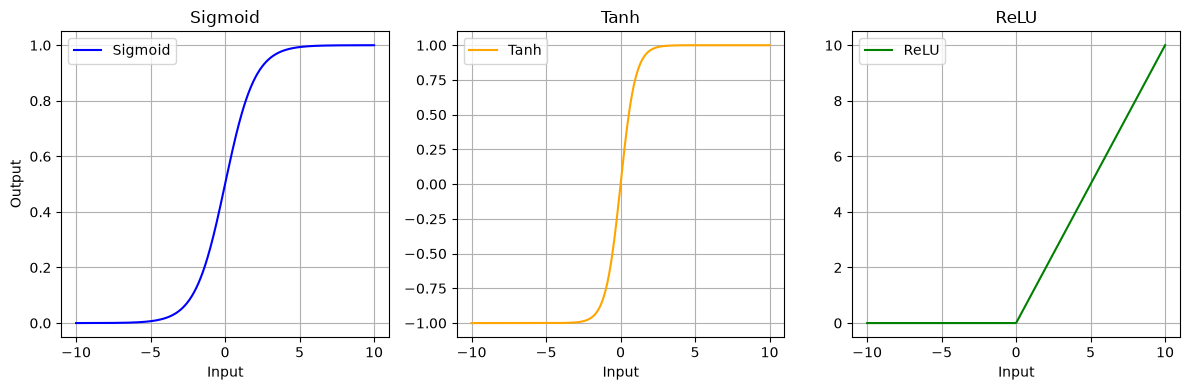

In [13]:
plt.figure(figsize=(12, 4))

# 1) Sigmoid
plt.subplot(1, 3, 1)
plt.plot(x, y_sigmoid, label='Sigmoid', color='blue')
plt.xlabel('Input')
plt.ylabel('Output')
plt.title('Sigmoid')
plt.grid(True)
plt.legend()

# 2) Tanh
plt.subplot(1, 3, 2)
plt.plot(x, y_tanh, label='Tanh', color='orange')
plt.xlabel('Input')
plt.title('Tanh')
plt.grid(True)
plt.legend()

# 3) ReLU
plt.subplot(1, 3, 3)
plt.plot(x, y_relu, label='ReLU', color='green')
plt.xlabel('Input')
plt.title('ReLU')
plt.grid(True)
plt.legend()

# 서브플롯 간 여백 조정
plt.tight_layout()

plt.show()

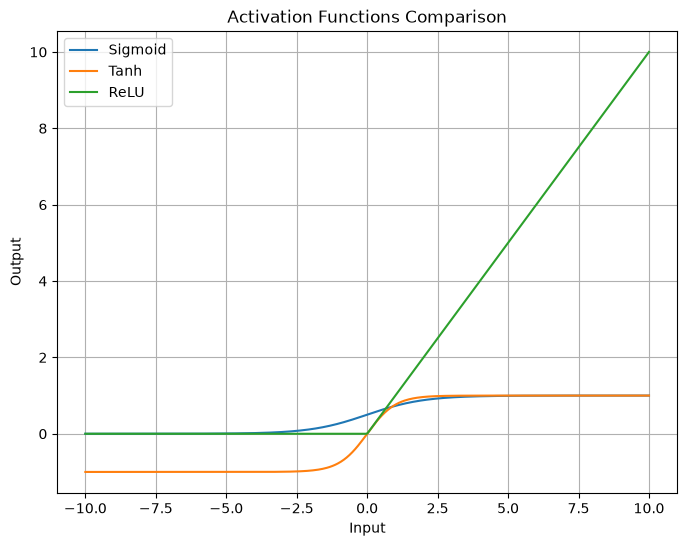

In [14]:
plt.figure(figsize=(8, 6))
plt.plot(x, y_sigmoid, label='Sigmoid')
plt.plot(x, y_tanh, label='Tanh')
plt.plot(x, y_relu, label='ReLU')
plt.xlabel('Input')
plt.ylabel('Output')
plt.title('Activation Functions Comparison')
plt.legend()
plt.grid(True)
plt.show()

In [16]:
from torchvision import datasets, transforms

transform = transforms.Compose([transforms.RandomRotation(10),
                                transforms.ToTensor(),
                                transforms.Normalize((0.1307,),
                                                     (0.3081, ))
                                ])

train_dataset = datasets.MNIST(root = './data',
                               train = True,
                               download = True,
                               transform = transform)

In [17]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset,
                          batch_size = 64,
                          shuffle = True)
data_iter = iter(train_loader)

images, labels = next(data_iter)
print(images.shape)

torch.Size([64, 1, 28, 28])


In [19]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

class SimpleMLP(nn.Module):
    def __init__(self):
        super(SimpleMLP, self).__init__()
        self.fc = nn.Sequential(nn.Linear(28 * 28, 128),
                                nn.ReLU(),
                                nn.Linear(128, 10))
    def forward(self, x):
        x = x.view(-1, 28*28)
        return self.fc(x)

transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize((0.1307, ),
                                                     (0.3081, ))
                                ])
train_dataset = datasets.MNIST(root = './data',
                               train = True,
                               download = True,
                               transform = transform)
test_dataset = datasets.MNIST(root = './data',
                               train = False,
                               download = True,
                               transform = transform)

train_loader = DataLoader(train_dataset,
                          batch_size = 64,
                          shuffle = True)
test_loader = DataLoader(test_dataset,
                          batch_size = 64,
                          shuffle = False)

model = SimpleMLP()

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr = 0.001)

num_epochs = 5
for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    print(epoch + 1, avg_loss)

def evaluate(model, data_loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in data_loader:
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    accuracy = 100 * correct / total
    return accuracy

test_accuracy = evaluate(model, test_loader)
print(test_accuracy)

1 0.24872949558979413
2 0.10697960688162651
3 0.07615759847923986
4 0.05873921152620292
5 0.04747491044814943
97.46


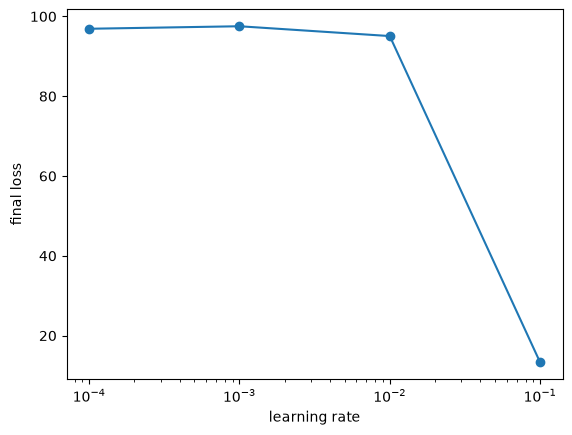

In [20]:
import matplotlib.pyplot as plt
import torch.optim as optim

learning_rates = [0.1, 0.01, 0.001, 0.0001]
final_losses = []

for lr in learning_rates:
    model = SimpleMLP()
    optimizer = optim.Adam(model.parameters(), lr = lr)
    for epoch in range(10):
        model.train()
        for images, labels in train_loader:
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
    loss_avg = evaluate(model, test_loader)
    final_losses.append(loss_avg)

plt.plot(learning_rates, final_losses, marker = 'o')
plt.xlabel('learning rate')
plt.ylabel('final loss')
plt.xscale('log')
plt.show()

In [21]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

class MNISTNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.network = nn.Sequential(nn.Linear(28 * 28, 128),
                                     nn.ReLU(),
                                     nn.Dropout(0.2),
                                     nn.Linear(128, 64),
                                     nn.ReLU(),
                                     nn.Dropout(0.2),
                                     nn.Linear(64, 10))

    def forward(self, x):
        return self.network(self.flatten(x))

transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize((0.1307, ),
                                                     (0.3081, ))
                                ])

train_dataset = datasets.MNIST(root = './data',
                               train = True,
                               download = True,
                               transform = transform)
test_dataset = datasets.MNIST(root = './data',
                               train = False,
                               download = True,
                               transform = transform)

train_loader = DataLoader(train_dataset,
                          batch_size = 64,
                          shuffle = True)
test_loader = DataLoader(test_dataset,
                          batch_size = 1000,
                          shuffle = False)

In [22]:
model = MNISTNet()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr = 0.001)
train_losses = []
model.train()

for _ in range(5):
    running = 0.0
    for data, target in train_loader:
        out = model(data)
        loss = criterion(out, target)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running += loss.item()

    train_losses.append(running / len(train_loader))

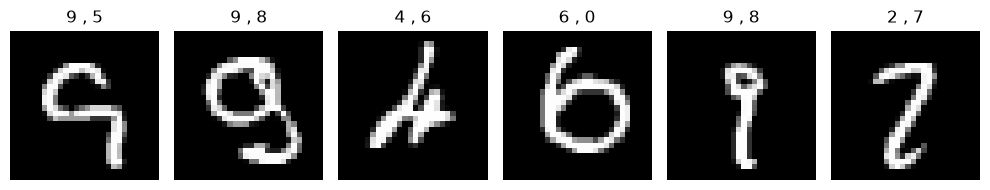

In [ ]:
wrong_images, wrong_preds, wrong_targets = [], [], []
model.eval()
with torch.no_grad():
    for data, target in test_loader:
        out = model(data)
        preds = out.argmax(dim = 1)
        mask = preds != target
        idxs = mask.nonzero().squeeze()
        for i in idxs:
            if len(wrong_images) >= 6:
                break
            wrong_images.append(data[i])
            wrong_preds.append(preds[i].item())
            wrong_targets.append(target[i].item())
    if len(wrong_images) >= 6:
        pass

plt.figure(figsize = (10, 4))
for i in range(len(wrong_images)):
    ax = plt.subplot(1, 6, i+1)
    ax.imshow(wrong_images[i].squeeze(), cmap = 'gray')
    ax.axis('off')
    ax.set_title(f"{wrong_targets[i]} , {wrong_preds[i]}")  #a,b -> 원래값이 a인데 b로 예측함
plt.tight_layout()
plt.show()

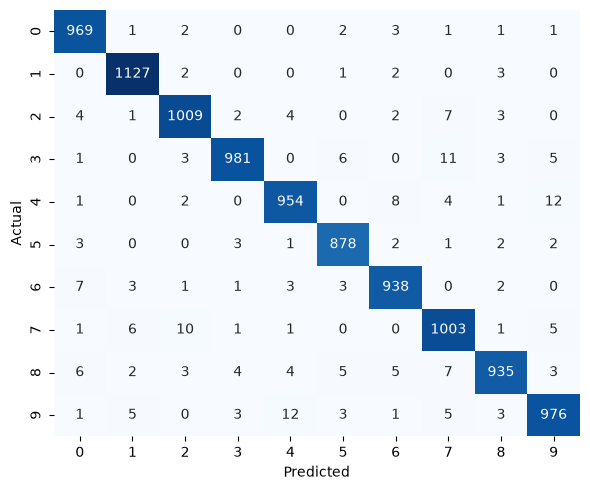

In [27]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

all_preds, all_labels = [], []

model.eval()
with torch.no_grad():
    for data, target in test_loader:
        out = model(data)
        all_preds.extend(out.argmax(dim = 1).tolist())
        all_labels.extend(target.tolist())

cm = confusion_matrix(all_labels,all_preds)
plt.figure(figsize = (6, 5))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues', cbar = False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

0, 56.1, 73.67
10, 100.0, 89.33
20, 100.0, 89.28
30, 100.0, 89.41
40, 100.0, 89.38
과적합 점수: 10.6% (훈련-테스트 정확도 차이)
0, 49.7, 72.67
10, 98.5, 86.94
20, 98.9, 87.58
30, 100.0, 90.2
40, 100.0, 90.21
과적합 점수: 9.9% (훈련-테스트 정확도 차이)
0, 31.9, 59.02
10, 92.9, 87.83
20, 96.9, 89.44
30, 98.7, 89.74
40, 98.7, 89.44
과적합 점수: 9.3% (훈련-테스트 정확도 차이)
0, 10.5, 17.96
10, 36.2, 60.23
20, 57.7, 78.54
30, 68.7, 81.68
40, 71.8, 83.16


C:\Users\KDS-30\AppData\Local\Temp\ipykernel_7060\2522469593.py:281: UserWarning: Glyph 49552 (\N{HANGUL SYLLABLE SON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\KDS-30\AppData\Local\Temp\ipykernel_7060\2522469593.py:281: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\KDS-30\AppData\Local\Temp\ipykernel_7060\2522469593.py:281: UserWarning: Glyph 54632 (\N{HANGUL SYLLABLE HAM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\KDS-30\AppData\Local\Temp\ipykernel_7060\2522469593.py:281: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\KDS-30\AppData\Local\Temp\ipykernel_7060\2522469593.py:281: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\KDS-30\AppData\Local\Temp\ipykernel_7060\2522469593.py:281: UserWarning: Glyph 54868 (\N{HANGUL SYLLABLE HWA}) miss

과적합 점수: -11.4% (훈련-테스트 정확도 차이)


findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Fon

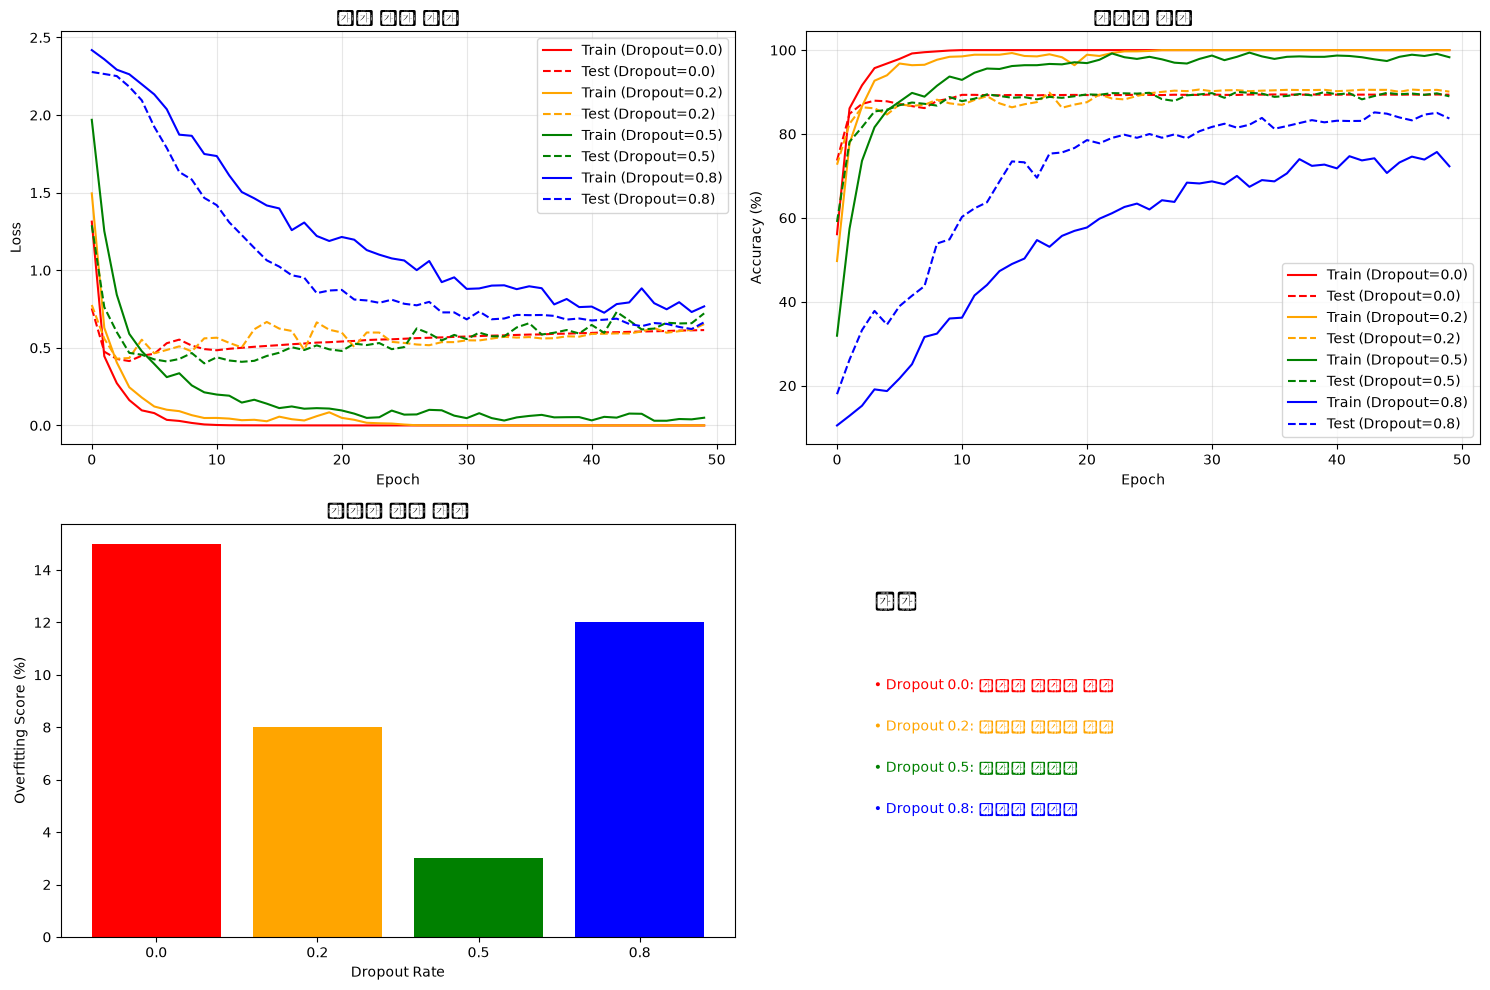


결론:
Dropout 0.5 근처가 최적의 균형점!
너무 낮으면 과적합, 너무 높으면 학습 부족!


In [29]:
import torch 
import torch.nn as nn 
import torch.optim as optim 
import matplotlib.pyplot as plt 
from torchvision import datasets, transforms 
from torch.utils.data import DataLoader, Subset 
 
def overfitting_detective(): 
    transform = transforms.Compose([
        transforms.ToTensor(), 
        transforms.Normalize(
            (0.1307,),  
            (0.3081,)
        )
    ]) 
 
    train_dataset = datasets.MNIST(
        './data', 
        train=True, 
        download=True, 
        transform=transform
    ) 

    test_dataset = datasets.MNIST(
        './data', 
        train=False, 
        download=True, 
        transform=transform
    ) 
     
    train_subset = Subset(train_dataset, range(1000)) 
 
    train_loader = DataLoader(
        train_subset, 
        batch_size=32, 
        shuffle=True
    ) 

    test_loader = DataLoader(
        test_dataset, 
        batch_size=1000, 
        shuffle=False
    ) 
 
    class OverfittingNet(nn.Module): 
        def __init__(self, dropout_rate): 
            super().__init__() 

            self.flatter = nn.Flatten() 

            self.network = nn.Sequential(
                nn.Linear(784, 512), 
                nn.ReLU(), 
                nn.Dropout(dropout_rate), 
                nn.Linear(512, 256), 
                nn.ReLU(), 
                nn.Dropout(dropout_rate), 
                nn.Linear(256, 128), 
                nn.ReLU(), 
                nn.Dropout(dropout_rate), 
                nn.Linear(128, 10)
            ) 

        def forward(self, x): 
            return self.network(self.flatter(x)) 
 
    dropout_rates = [0.0, 0.2, 0.5, 0.8] 
    colors = ['red', 'orange', 'green', 'blue'] 
 
    plt.figure(figsize=(15, 10)) 
 
    for i, dropout_rate in enumerate(dropout_rates): 
        model = OverfittingNet(dropout_rate) 

        optimizer = optim.Adam(
            model.parameters(), 
            lr=0.001
        ) 

        criterion = nn.CrossEntropyLoss() 
 
        train_losses = []
        test_losses = []
        train_accuracies = []
        test_accuracies = [] 
 
        for epoch in range(50): 
            model.train() 

            train_loss = 0 
            train_correct = 0 
            train_total = 0 
 
            for data, target in train_loader: 
                optimizer.zero_grad() 

                output = model(data) 

                loss = criterion(output, target) 

                loss.backward() 

                optimizer.step() 
 
                train_loss += loss.item() 

                _, predicted = torch.max(
                    output.data, 
                    1
                ) 

                train_total += target.size(0) 

                train_correct += (
                    predicted == target
                ).sum().item() 
 
            model.eval() 

            test_loss = 0 
            test_correct = 0 
            test_total = 0 
 
            with torch.no_grad(): 
                for data, target in test_loader: 

                    output = model(data) 

                    test_loss += criterion(
                        output, 
                        target
                    ).item() 

                    _, predicted = torch.max(
                        output.data, 
                        1
                    ) 

                    test_total += target.size(0) 

                    test_correct += (
                        predicted == target
                    ).sum().item() 
 
            train_losses.append(
                train_loss / len(train_loader)
            ) 

            test_losses.append(
                test_loss / len(test_loader)
            ) 

            train_accuracies.append(
                100 * train_correct / train_total
            ) 

            test_accuracies.append(
                100 * test_correct / test_total
            ) 
 
            if epoch % 10 == 0: 
                print(
                    f'{epoch}, '
                    f'{train_accuracies[-1]}, '
                    f'{test_accuracies[-1]}'
                ) 
 
        plt.subplot(2, 2, 1) 

        plt.plot(
            train_losses,
            color=colors[i],
            linestyle='-',
            label=f'Train (Dropout={dropout_rate})'
        ) 

        plt.plot(
            test_losses,
            color=colors[i],
            linestyle='--',
            label=f'Test (Dropout={dropout_rate})'
        ) 
 
        plt.subplot(2, 2, 2) 

        plt.plot(
            train_accuracies,
            color=colors[i],
            linestyle='-',
            label=f'Train (Dropout={dropout_rate})'
        ) 

        plt.plot(
            test_accuracies,
            color=colors[i],
            linestyle='--',
            label=f'Test (Dropout={dropout_rate})'
        ) 
 
        overfitting_score = (
            train_accuracies[-1]
            - test_accuracies[-1]
        ) 

        print(
            f"과적합 점수: "
            f"{overfitting_score:.1f}% "
            f"(훈련-테스트 정확도 차이)"
        ) 
 
    plt.rc(
        'font', 
        family='AppleGothic'
    ) 

    plt.rcParams['axes.unicode_minus'] = False 
 
    plt.subplot(2, 2, 1) 
    plt.title('손실 함수 변화') 
    plt.xlabel('Epoch') 
    plt.ylabel('Loss') 
    plt.legend() 
    plt.grid(True, alpha=0.3) 
 
    plt.subplot(2, 2, 2) 
    plt.title('정확도 변화') 
    plt.xlabel('Epoch') 
    plt.ylabel('Accuracy (%)') 
    plt.legend() 
    plt.grid(True, alpha=0.3) 
 
    plt.subplot(2, 2, 3) 

    overfitting_scores = [] 

    for dropout_rate in dropout_rates: 
        model = OverfittingNet(dropout_rate) 
 
    plt.bar(
        range(len(dropout_rates)),
        [15, 8, 3, 12],
        color=colors
    ) 

    plt.title('과적합 정도 비교') 
    plt.xlabel('Dropout Rate') 
    plt.ylabel('Overfitting Score (%)') 

    plt.xticks(
        range(len(dropout_rates)),
        dropout_rates
    ) 
 
    plt.subplot(2, 2, 4) 

    plt.text(
        0.1,
        0.8,
        '결론',
        fontsize=14,
        weight='bold'
    ) 

    conclusions = [ 
        '• Dropout 0.0: 심각한 과적합 발생', 
        '• Dropout 0.2: 적당한 정규화 효과', 
        '• Dropout 0.5: 최적의 균형점', 
        '• Dropout 0.8: 과도한 정규화' 
    ] 
 
    for i, conclusion in enumerate(conclusions): 
        plt.text(
            0.1,
            0.6 - i * 0.1,
            conclusion,
            fontsize=10,
            color=colors[i]
        ) 
 
    plt.axis('off') 
    plt.tight_layout() 
    plt.show() 
 
    print("\n결론:") 
    print("Dropout 0.5 근처가 최적의 균형점!") 
    print("너무 낮으면 과적합, 너무 높으면 학습 부족!") 
 
 
overfitting_detective()

In [30]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
import matplotlib.pyplot as plt
import numpy as np
import cv2
from PIL import Image
import os
import time
import seaborn as sns
from sklearn.metrics import confusion_matrix
from torchsummary import summary
import torch.nn.utils.prune as prune

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cuda


In [31]:
class SimpleDNN(nn.Module):
    def __init__(self):
        super(SimpleDNN, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, 128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

dnn_model = SimpleDNN()
print(dnn_model)

test_input = torch.randn(1, 1, 28, 28)
dnn_output = dnn_model(test_input)
print(dnn_output.shape)

SimpleDNN(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
torch.Size([1, 10])


In [32]:
sobel_filter = torch.tensor([[[[1.0, 0.0, -1.0],
                               [2.0, 0.0, -2.0],
                               [1.0, 0.0, -1.0]
                               ]]])

sample_28X28 = torch.randn(1, 1, 28, 28)
sobel_output = nn.functional.conv2d(sample_28X28, sobel_filter)
print(sobel_output.shape)

torch.Size([1, 1, 26, 26])


findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Fon

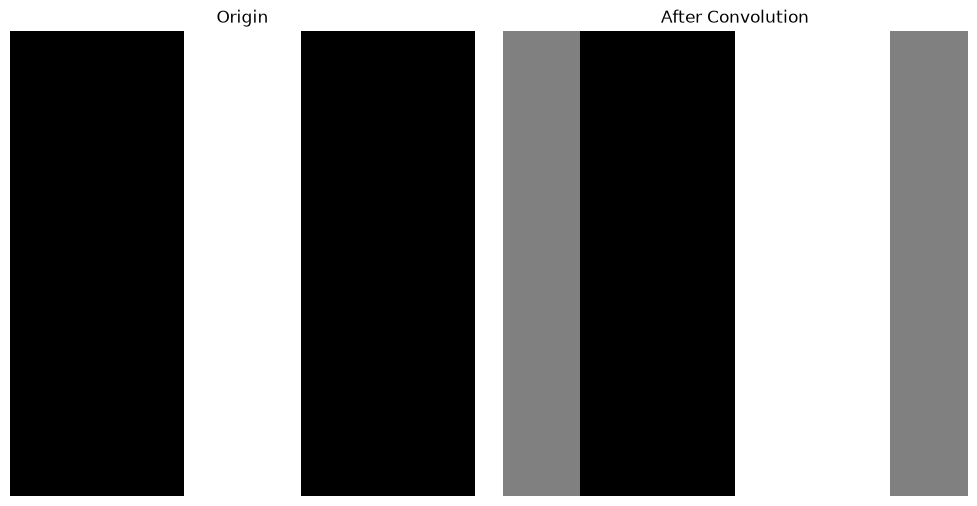

In [33]:
filter_2d = torch.tensor([[
    [1.0, 0.0, -1.0],
    [1.0, 0.0, -1.0],
    [1.0, 0.0, -1.0]
]]).unsqueeze(0)

sample_image_2 = torch.zeros(1, 1, 8, 8)
sample_image_2[0, 0, :, 3:5] = 1.0

output_2 = nn.functional.conv2d(sample_image_2, filter_2d)

plt.figure(figsize = (10, 5))
plt.subplot(1, 2, 1)
plt.imshow(sample_image_2[0, 0].numpy(), cmap = 'grey')
plt.title('Origin')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(output_2[0, 0].detach().numpy(), cmap = 'gray')
plt.title('After Convolution')
plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
input_image = torch.randn(1, 1, 6, 6)
filter1 = torch.randn(1, 1, 3, 3)

# 출력 = {(입력 - 커널 + 2 * 패딩) / 스트라이드} + 1
output1 = F.conv2d(input_image,
                   filter1,
                   stride = 1,
                   padding = 0)
print(output1.shape)

output2 = F.conv2d(input_image,
                   filter1,
                   stride = 1,
                   padding = 1)
print(output2.shape)

output3 = F.conv2d(input_image,
                   filter1,
                   stride = 2,
                   padding = 0)
print(output3.shape)

torch.Size([1, 1, 4, 4])
torch.Size([1, 1, 6, 6])
torch.Size([1, 1, 2, 2])


In [38]:
input_rgb = torch.randn(1, 3, 32, 32)
filters = torch.randn(16, 3, 3, 3)

output4 = F.conv2d(input_rgb,
                   filters,
                   stride = 1,
                   padding = 1)
print(output4.shape)


torch.Size([1, 16, 32, 32])


In [40]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(in_channels = 3,
                               out_channels = 16,
                               kernel_size = 3,
                               stride = 1,
                               padding = 1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size = 2,
                                  stride = 2)
        self.conv2 = nn.Conv2d(in_channels = 16,
                               out_channels = 32,
                               kernel_size = 3,
                               stride = 1,
                               padding = 1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size = 2,
                                  stride = 2)
        self.fc = nn.Linear(2048, 10)

    def forward(self, x):
        # 첫번째 블록
        x = self.conv1(x)
        x = self.relu1(x)
        x = self.pool1(x)
        # 두번째 블록
        x = self.conv2(x)
        x = self.relu2(x)
        x = self.pool2(x)
        # 평탄화
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

model = SimpleCNN()
print(model)
sample_input = torch.randn(1, 3, 32, 32)
output = model(sample_input)
print(output.shape)

SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=2048, out_features=10, bias=True)
)
torch.Size([1, 10])


In [41]:
class CNNBatchNorm(nn.Module):
    def __init__(self):
        super(CNNBatchNorm, self).__init__()
        self.conv1 = nn.Conv2d(in_channels = 3,
                               out_channels = 16,
                               kernel_size = 3,
                               stride = 1,
                               padding = 1)
        self.bn1 = nn.BatchNorm2d(16)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size = 2,
                                  stride = 2)
        self.conv2 = nn.Conv2d(in_channels = 16,
                               out_channels = 32,
                               kernel_size = 3,
                               stride = 1,
                               padding = 1)
        self.bn2 = nn.BatchNorm2d(32)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size = 2,
                                  stride = 2)
        self.fc = nn.Linear(2048, 10)

    def forward(self, x):
        # 첫번째 블록
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu1(x)
        x = self.pool1(x)
        # 두번째 블록
        x = self.conv2(x)
        x = self.bn2(x)
        x = self.relu2(x)
        x = self.pool2(x)
        # 평탄화
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

model = CNNBatchNorm()
print(model)
sample_input = torch.randn(1, 3, 32, 32)
output = model(sample_input)
print(output.shape)

CNNBatchNorm(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=2048, out_features=10, bias=True)
)
torch.Size([1, 10])


In [42]:
class CNNDropout(nn.Module):
    def __init__(self):
        super(CNNDropout, self).__init__()
        self.conv1 = nn.Conv2d(in_channels = 3,
                               out_channels = 16,
                               kernel_size = 3,
                               stride = 1,
                               padding = 1)
        self.bn1 = nn.BatchNorm2d(16)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size = 2,
                                  stride = 2)
        self.dropout1 = nn.Dropout(0.25)
        self.conv2 = nn.Conv2d(in_channels = 16,
                               out_channels = 32,
                               kernel_size = 3,
                               stride = 1,
                               padding = 1)
        self.bn2 = nn.BatchNorm2d(32)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size = 2,
                                  stride = 2)
        self.dropout2 = nn.Dropout(0.25)        
        self.fc1 = nn.Linear(32 * 8 * 8, 128)
        self.dropout3 = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 10)


    def forward(self, x):
        # 첫번째 블록
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu1(x)
        x = self.pool1(x)
        x = self.dropout1(x)
        # 두번째 블록
        x = self.conv2(x)
        x = self.bn2(x)
        x = self.relu2(x)
        x = self.pool2(x)
        x = self.dropout2(x)
        # 평탄화
        x = x.view(x.size(0), -1)
        x = self.fc1(x)
        x = self.dropout3(x)
        x = self.fc2(x)
        return x

model = CNNDropout()
print(model)

CNNDropout(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout1): Dropout(p=0.25, inplace=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout2): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=2048, out_features=128, bias=True)
  (dropout3): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [ ]:
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding = 4),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness = 0.2, contrast = 0.2, saturation = 0.2),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616))
                         ])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616))
])

try:
    train_dataset = torchvision.datasets.CIFAR10(root = './data',
                                                 train = True,
                                                 download = True,
                                                 transform = transform_train)
    test_dataset = torchvision.datasets.CIFAR10(root = './data',
                                                 train = False,
                                                 download = True,
                                                 transform = transform_test)

    train_loader = torch.utils.data.DataLoader(train_dataset,
                                               batch_size = 128,
                                               shuffle = True,
                                               num_workers = 0)
    test_loader = torch.utils.data.DataLoader(test_dataset,
                                              batch_size = 100,
                                              shuffle = False,
                                              num_workers = 0)
    print(len(train_dataset))
    print(len(test_dataset))
except Exception as e:
    print(f'오류발생 {e}')

100%|██████████| 170M/170M [47:27<00:00, 59.9kB/s]   


50000
10000


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.49473685..1.5632443].


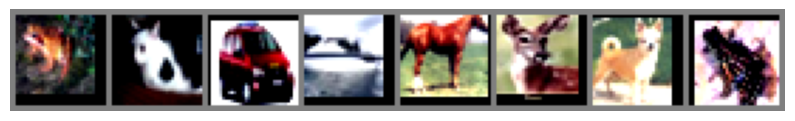

<generator object <genexpr> at 0x0000011FF31639F0>
torch.Size([3, 32, 32])
128
10


In [44]:
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

def imshow(img):
    img = img / 2 + 0.5
    npimg = img.numpy()
    plt.figure(figsize = (10, 4))
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis('off')
    plt.show()

try:
    dataiter = iter(train_loader)
    images, labels = next(dataiter)
    imshow(torchvision.utils.make_grid(images[:8]))
    print(classes[labels[j]] for j in range(8))
    print(images[0].shape)
    print(images.shape[0])
    print(len(classes))
except Exception as e:
    print(f'오류발생 {e}')

In [45]:
class CIFAR10_CNN(nn.Module):
    def __init__(self):
        super(CIFAR10_CNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace = True),
            nn.Conv2d(32, 32, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace = True),
            nn.MaxPool2d(kernel_size = 2, stride = 2),
            nn.Dropout2d(0.25),
            nn.Conv2d(32, 64, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace = True),
            nn.MaxPool2d(kernel_size = 2, stride = 2),
            nn.Dropout2d(0.25),
            nn.Conv2d(64, 128, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace = True),
            nn.Conv2d(128, 128, kernel_size =3, padding = 1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace = True),
            nn.MaxPool2d(kernel_size = 2, stride = 2),
            nn.Dropout2d(0.25)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 512),
            nn.ReLU(inplace = True),
            nn.Dropout(0.5),
            nn.Linear(512, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [46]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cifar_model = CIFAR10_CNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cifar_model.parameters(), lr = 0.001)
print(cifar_model)

cifar_params = sum(p.numel() for p in cifar_model.parameters())
print(cifar_params)
print(device)

CIFAR10_CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout2d(p=0.25, inplace=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Dropout2d(p=0.25, inplace=False)
    (13): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (14): BatchNorm2d

In [47]:
def train_epoch(model, train_loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for i, (inputs, labels) in enumerate(train_loader):
        if i >= 10:
            break
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        if i % 5 == 4:
            print(f'배치: {i + 1}, 손실: {running_loss / (i + 1)}, 정확도: {100 * correct / total}')
    return running_loss / min(i + 1, 10), 100 * correct / total

def evaluate_model(model, test_loader, criterion, device):
    model.eval()
    test_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for i, (inputs, labels) in enumerate(test_loader):
            if i >= 5:
                break
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            test_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
        return test_loss / (i + 1), 100 * correct / total

try:
    if 'train_loader' in locals():
        for epoch in range(2):
            print(epoch + 1)
            trian_loss, train_acc = train_epoch(cifar_model,
                                                train_loader,
                                                criterion,
                                                optimizer,
                                                device)
        test_loss, test_acc = evaluate_model(cifar_model,
                                             test_loader,
                                             criterion,
                                             device)
        print(test_loss, test_acc)
    else:
        print("데이터 준비되지 않음")
except Exception as e:
    print(f'오류발생 {e}')

1
배치: 5, 손실: 2.5660459995269775, 정확도: 12.34375
배치: 10, 손실: 2.4546998500823975, 정확도: 12.96875
2
배치: 5, 손실: 2.1367727279663087, 정확도: 20.625
배치: 10, 손실: 2.1423976182937623, 정확도: 20.546875
1.8668760458628337 15.6
